In [64]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt

In [65]:

expression = "x**2 - 8*cos(2*pi*x) + 8"

a = -5.12
b = 5.12
eps = 0.01

def f(x):
    allowed = {
        "x": x,
        "sin": math.sin,
        "cos": math.cos,
        "exp": math.exp,
        "sqrt": math.sqrt,
        "pi": math.pi
    }
    return float(eval(expression, {"__builtins__": {}}, allowed))

print("Функция:", expression)
print("Отрезок:", a, b)
print("Точность:", eps)


Функция: x**2 - 8*cos(2*pi*x) + 8
Отрезок: -5.12 5.12
Точность: 0.01


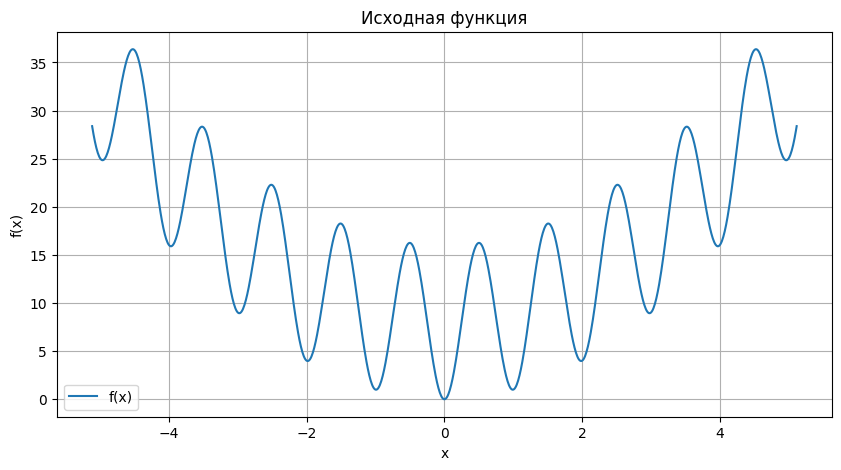

In [66]:
x_values = np.linspace(a, b, 1000)
y_values = [f(x) for x in x_values]

plt.figure(figsize=(10, 5))
plt.plot(x_values, y_values, label="f(x)")
plt.title("Исходная функция")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.show()

In [67]:

# Для W(x) = x**2 - 8*cos(2*pi*x) + 8
# W'(x) = 2*x + 16*pi*sin(2*pi*x)

L = 2 * max(abs(a), abs(b)) + 16 * math.pi

print("Константа Липшица:", round(L, 5))


Константа Липшица: 60.50548


In [68]:

def broken_line_method(f, a, b, eps, L, max_iter=10000):
    if a >= b or eps <= 0 or L <= 0 or max_iter < 1:
        raise ValueError("некорректные параметры метода")

    start = time.perf_counter()

    points = [(a, f(a)), (b, f(b))]
    point_order = points.copy()
    history = []

    converged = False
    stop_reason = "Достигнут предел итераций"

    for step in range(max_iter):
        points.sort()
        candidates = []

        for i in range(len(points) - 1):
            x1, y1 = points[i]
            x2, y2 = points[i + 1]

            x_new = (x1 + x2) / 2 + (y1 - y2) / (2 * L)
            lower = (y1 + y2 - L * (x2 - x1)) / 2

            candidates.append((lower, x_new))

        lower, x_new = min(candidates)

        best_x, best_y = min(points, key=lambda p: p[1])
        gap = max(0.0, best_y - lower)

        history.append((step + 1, best_y, lower, gap))

        if gap <= eps:
            converged = True
            stop_reason = "достигнута заданная точность"
            break

        if any(abs(x_new - x) < 1e-12 for x, _ in points):
            stop_reason = "новая точка совпадает с уже найденной"
            break

        new_point = (x_new, f(x_new))
        points.append(new_point)
        point_order.append(new_point)

    points.sort()

    best_x, best_y = min(points, key=lambda p: p[1])
    elapsed = time.perf_counter() - start

    return (best_x, best_y, points, point_order,
            history, elapsed, converged, stop_reason)


In [69]:

x_min, y_min, points, point_order, history, elapsed, converged, stop_reason = broken_line_method(
    f, a, b, eps, L
)

print("L =", round(L, 5))
print("найденная точка:", round(x_min, 6))
print("значение функции:", round(y_min, 6))
print("количество итераций:", len(history))
print("количество пробных точек:", len(points))
print("время работы:", round(elapsed, 5), "сек")
print("достигнутая точность:", round(history[-1][3], 6))

print("причина остановки:", stop_reason)

if converged:
    print("метод успешно завершился")
else:
    print("заданная точность не достигнута")


L = 60.50548
найденная точка: 0.0
значение функции: 0.0
количество итераций: 148
количество пробных точек: 149
время работы: 0.01001 сек
достигнутая точность: 0.009038
причина остановки: достигнута заданная точность
метод успешно завершился


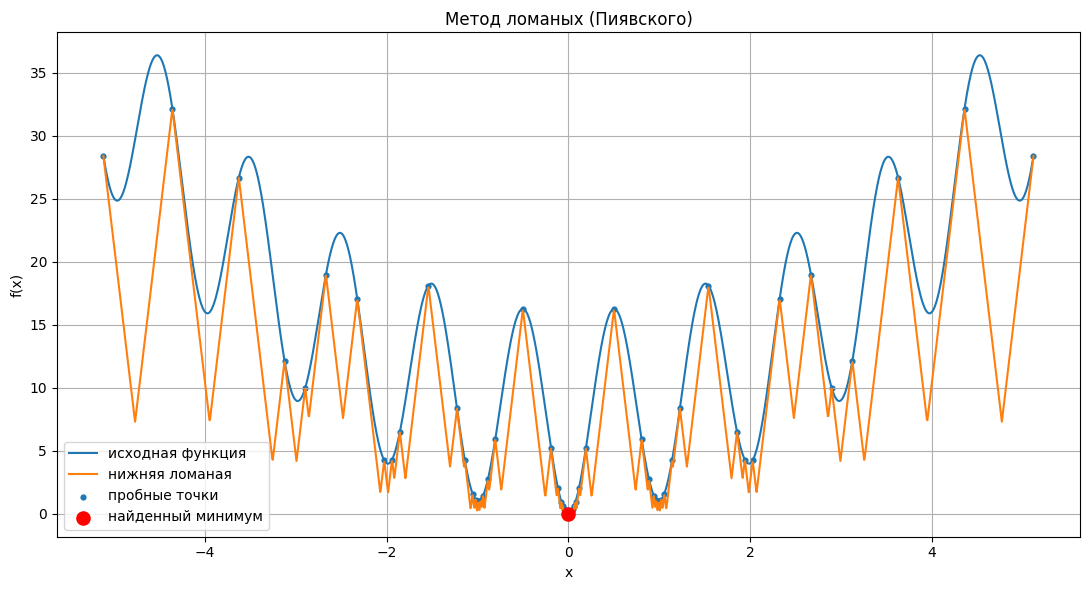

In [70]:
def get_lower_line(xs, points, L):
    line = np.full(len(xs), -np.inf)

    for x, y in points:
        current = y - L * np.abs(xs - x)
        line = np.maximum(line, current)

    return line


xs = np.linspace(a, b, 2000)
ys = np.array([f(x) for x in xs])
lower_line = get_lower_line(xs, points, L)

plt.figure(figsize=(11, 6))

plt.plot(xs, ys, label="исходная функция")
plt.plot(xs, lower_line, label="нижняя ломаная")

px = [p[0] for p in points]
py = [p[1] for p in points]

plt.scatter(px, py, s=12, label="пробные точки")
plt.scatter(x_min, y_min, color="red", s=90,
            label="найденный минимум", zorder=5)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Метод ломаных (Пиявского)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("result.png", dpi=200)
plt.show()

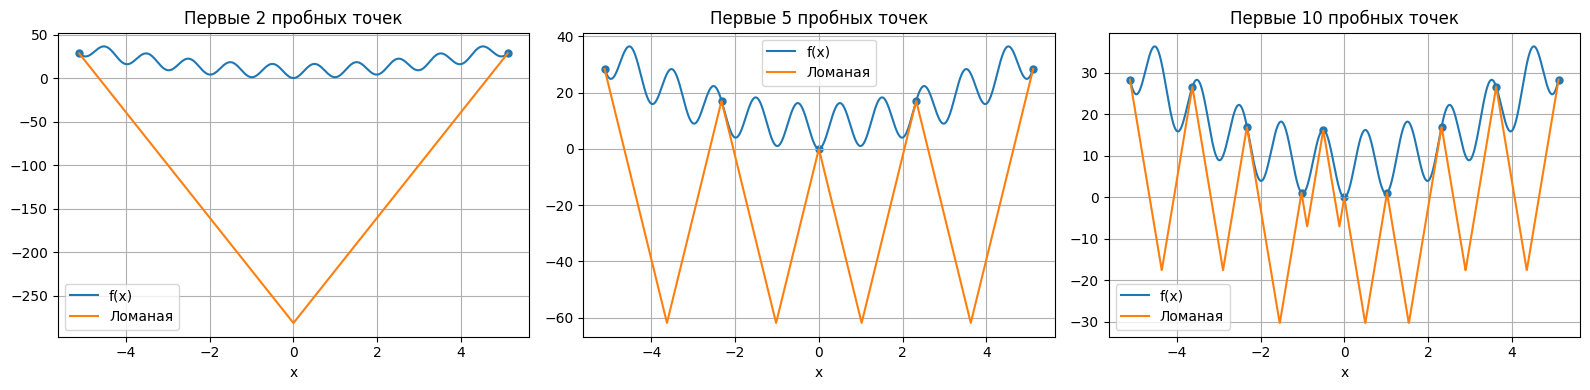

In [71]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, count in zip(axes, [2, 5, 10]):
    current_points = point_order[:count]
    current_line = get_lower_line(xs, current_points, L)

    ax.plot(xs, ys, label="f(x)")
    ax.plot(xs, current_line, label="Ломаная")

    ax.scatter(
        [p[0] for p in current_points],
        [p[1] for p in current_points],
        s=25
    )

    ax.set_title(f"Первые {count} пробных точек")
    ax.set_xlabel("x")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.savefig("steps.png", dpi=200)
plt.show()


In [72]:

print("Проверка результата ")

print("Найденный x: ", x_min)
print("Найденное W(x): ", y_min)


exact_x = 0
exact_y = f(exact_x)

print("Точный минимум x = ", exact_x)
print("Точное значение W(0) = ", exact_y)

print("Ошибка по аргументу:" , abs(x_min - exact_x))
print("Ошибка по функции: ", abs(y_min - exact_y))

if converged:
    print("Критерий остановки выполнен ")
else:
    print("Критерий остановки не достигнут ")


Проверка результата 
Найденный x:  0.0
Найденное W(x):  0.0
Точный минимум x =  0
Точное значение W(0) =  0.0
Ошибка по аргументу: 0.0
Ошибка по функции:  0.0
Критерий остановки выполнен 


In [73]:
# проверка на второй функции (тест)
def f2(x):
    return (x - 1)**2 + math.sin(x - 1)**2

a2 = -2
b2 = 4
L2 = 7

x2, y2, pts2, order2, hist2, t2, ok2, reason2 = broken_line_method(
    f2, a2, b2, eps, L2
)

print("проверка на второй функции")
print("найденная точка:", round(x2, 6))
print("значение функции:", round(y2, 6))
print("количество итераций:", len(hist2))
print("достигнутая точность:", round(hist2[-1][3], 6))
print("успешно:", ok2)


проверка на второй функции
найденная точка: 1.0
значение функции: 0.0
количество итераций: 108
достигнутая точность: 0.009356
успешно: True
